# 01 - Exploration et prétraitement des données (Personne 1)

**Objectif** : comprendre le dataset NEU, vérifier l'équilibre des classes, préparer le découpage
train / validation / test et valider les étapes de prétraitement.

Prérequis : le dataset brut NEU Surface Defect Database est décompressé dans `data_raw/`.

In [20]:
!ls /content/drive/MyDrive/metal-defect-detection
!echo "-----"
!ls /content/metal-defect-detection
!echo "-----"
!find /content -name "common.py" -not -path "*/dist-packages/*"

archive.zip  notebooks	src
-----
data_raw
-----
/content/drive/MyDrive/metal-defect-detection/src/common.py


In [21]:
from google.colab import drive
drive.mount('/content/drive')

# repartir de zéro
!rm -rf /content/metal-defect-detection
!cp -r /content/drive/MyDrive/metal-defect-detection /content/metal-defect-detection

# décompresser le dataset brut
!mkdir -p /content/metal-defect-detection/data_raw
!unzip -q /content/metal-defect-detection/archive.zip -d /content/metal-defect-detection/data_raw

# se placer dans notebooks/ (indispensable pour les imports src)
%cd /content/metal-defect-detection/notebooks
!pip install -q opencv-python-headless seaborn

# vérifications : src présent, et 1800 images attendues
!ls /content/metal-defect-detection/src
!find /content/metal-defect-detection/data_raw -type f \( -iname "*.bmp" -o -iname "*.png" -o -iname "*.jpg" \) | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
/content/metal-defect-detection/notebooks
common.py	__init__.py	     model.py
data_loader.py	make_dummy_model.py  prepare_dataset.py
1800


In [22]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.common import CLASS_NAMES, CLASS_LABELS_FR, DATA_RAW_DIR, DATASET_DIR, RESULTS_DIR, IMG_SIZE
from src.prepare_dataset import prepare

RESULTS_DIR.mkdir(exist_ok=True)
print("Racine du projet :", ROOT)

Racine du projet : /content/metal-defect-detection


In [23]:
import sys
from pathlib import Path

# Définit la racine du projet (s'adapte si on est dans le dossier notebooks ou à la racine)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Si le dossier du projet n'est pas le dossier courant mais est dans /content/metal-defect-detection
if not (ROOT / "src").exists() and Path("/content/drive/MyDrive/metal-defect-detection").exists():
    ROOT = Path("/content/drive/MyDrive/metal-defect-detection")

sys.path.insert(0, str(ROOT))

try:
    import cv2
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from src.common import CLASS_NAMES, CLASS_LABELS_FR, DATA_RAW_DIR, DATASET_DIR, RESULTS_DIR, IMG_SIZE
    from src.prepare_dataset import prepare

    RESULTS_DIR.mkdir(exist_ok=True)
    print("Racine du projet configurée avec succès :", ROOT)
except ModuleNotFoundError as e:
    print(f"Erreur d'importation : {e}")
    print("Veuillez vérifier que le dossier 'src' existe bien dans :", ROOT)

Racine du projet configurée avec succès : /content/metal-defect-detection


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Découpage Train / Validation / Test

Le script `prepare_dataset.py` classe les images par catégorie puis les répartit en **70 % / 15 % / 15 %**
de façon stratifiée, avec une graine fixe (`SEED = 42`). Personne 2 obtient exactement le même découpage.

Relancez avec `force=True` uniquement si vous voulez refaire le découpage.

In [24]:
try:
    counts = prepare(DATA_RAW_DIR, DATASET_DIR, force=False)   # mettre force=True pour refaire
except NameError as e:
    print("Erreur : La fonction 'prepare' n'est pas définie.")
    print("Veuillez d'abord résoudre l'erreur d'importation dans la cellule précédente (scQKks1OhT7X).")


1800 images réparties (graine = 42) :
classe              train   val  test
crazing               210    45    45
inclusion             210    45    45
patches               210    45    45
pitted_surface        210    45    45
rolled-in_scale       210    45    45
scratches             210    45    45


## 2. Les six catégories et l'équilibre des classes

,train,validation,test,total
crazing,210,45,45,300
inclusion,210,45,45,300
patches,210,45,45,300
pitted_surface,210,45,45,300
rolled-in_scale,210,45,45,300
scratches,210,45,45,300


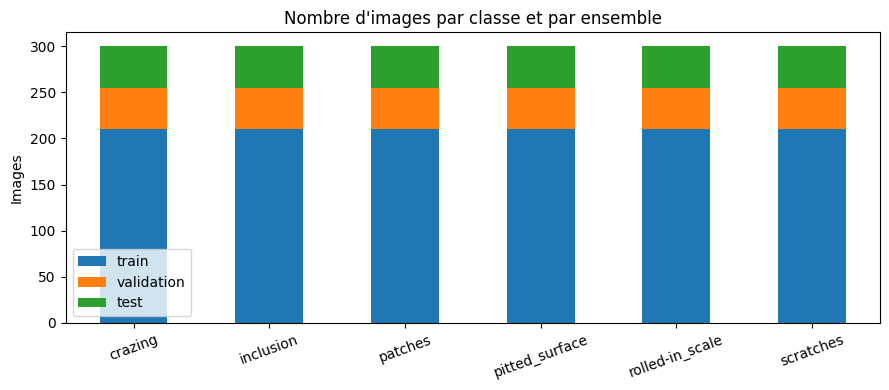

Équilibre : OK (classes équilibrées)


In [25]:
try:
    df = pd.DataFrame(counts).T[["train", "validation", "test"]]
    df["total"] = df.sum(axis=1)
    display(df)

    ax = df[["train", "validation", "test"]].plot(kind="bar", stacked=True, figsize=(9, 4), rot=20)
    ax.set_title("Nombre d'images par classe et par ensemble")
    ax.set_ylabel("Images")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=150)
    plt.show()

    print("Équilibre :", "OK (classes équilibrées)" if df["total"].nunique() == 1
          else f"classes déséquilibrées : min={df['total'].min()}, max={df['total'].max()}")
except NameError as e:
    print("Erreur : Impossible d'afficher les graphiques car la variable 'counts' n'est pas définie.")
    print("Veuillez d'abord résoudre l'importation de 'src' et exécuter la fonction 'prepare' dans les cellules précédentes.")

## 3. Visualisation de quelques images par catégorie

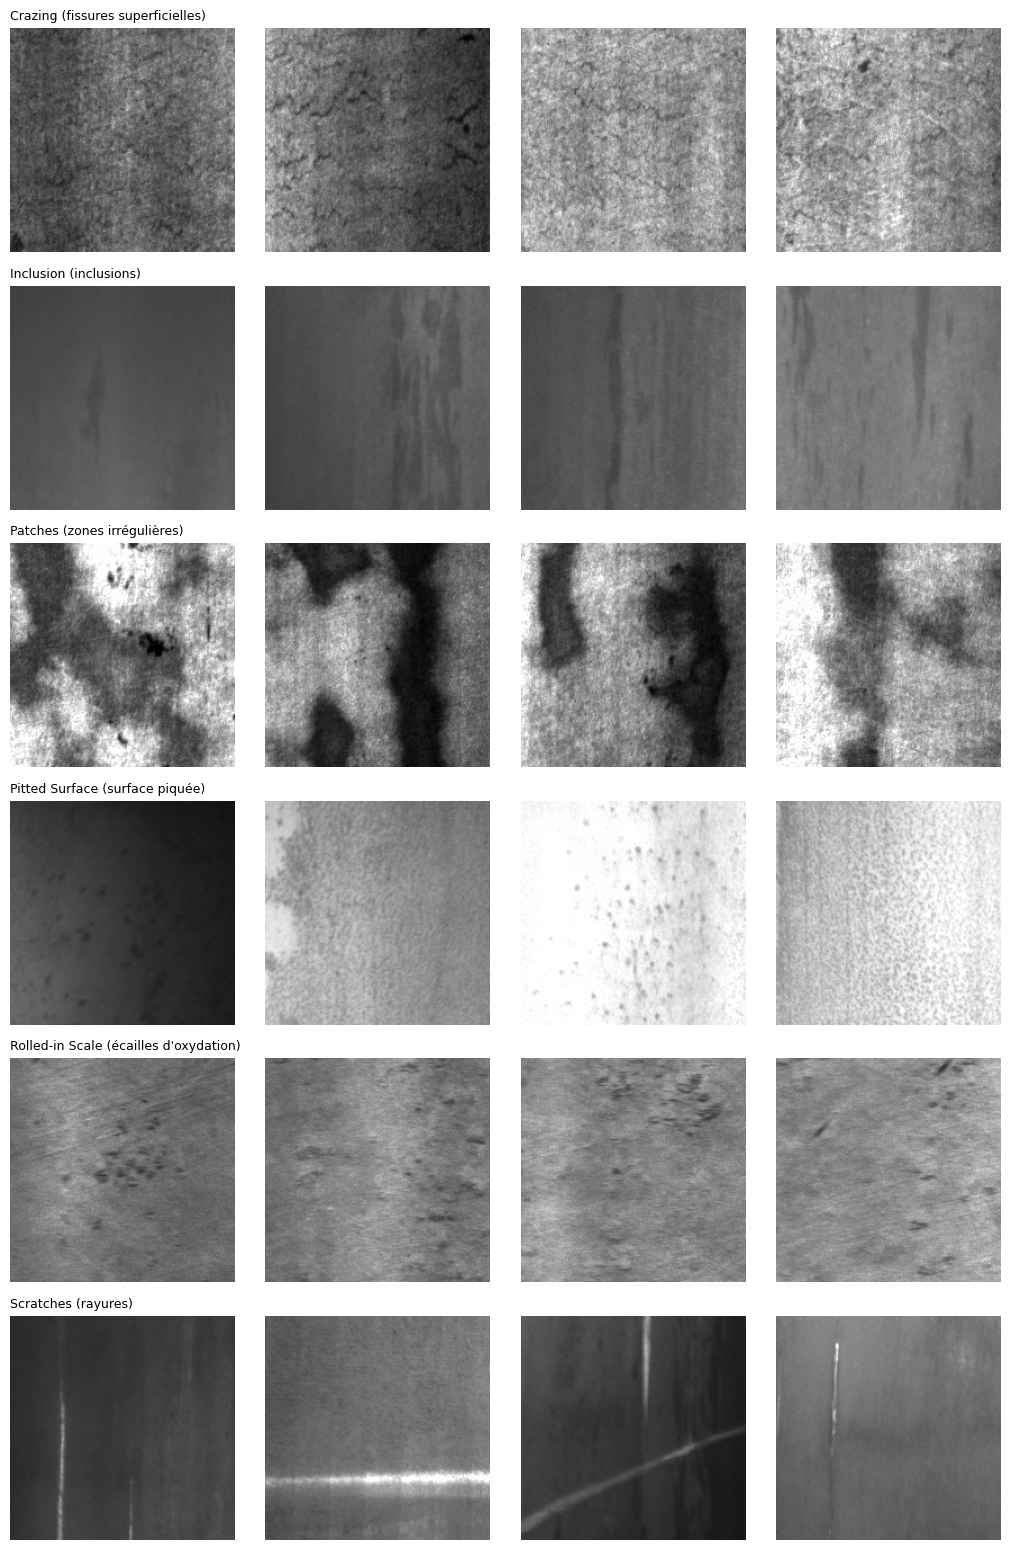

In [26]:
N = 4
fig, axes = plt.subplots(len(CLASS_NAMES), N, figsize=(2.6 * N, 2.6 * len(CLASS_NAMES)))
for r, cls in enumerate(CLASS_NAMES):
    files = sorted((DATASET_DIR / "train" / cls).glob("*"))[:N]
    for c, f in enumerate(files):
        img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(CLASS_LABELS_FR[cls], loc="left", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_images.png", dpi=120)
plt.show()

## 4. Vérification des images (taille, type, valeurs de pixels)

In [27]:
shapes, means = set(), []
for f in sorted((DATASET_DIR / "train").rglob("*"))[:300]:
    if f.is_file():
        img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        shapes.add(img.shape)
        means.append(img.mean())
print("Tailles d'image rencontrées :", shapes)
print(f"Luminosité moyenne : {np.mean(means):.1f} (min {np.min(means):.1f}, max {np.max(means):.1f})")

Tailles d'image rencontrées : {(200, 200)}
Luminosité moyenne : 132.4 (min 49.9, max 233.4)


## 5. Prétraitement : redimensionnement, normalisation, encodage

- **Redimensionnement** : 200 × 200 (taille native de NEU, appliquée par `image_dataset_from_directory`).
- **Niveaux de gris** : 1 canal.
- **Normalisation** : division par 255 pour passer de [0, 255] à [0, 1]. Elle est réalisée par la couche
  `Rescaling` placée **dans le modèle** : l'application Streamlit n'a donc qu'à fournir l'image redimensionnée.
- **Encodage des classes** : entiers 0 à 5 (ordre de `CLASS_NAMES`), loss `sparse_categorical_crossentropy`.

Brute      : shape=(200, 200), dtype=uint8, min=56, max=255
Normalisée : shape=(200, 200), dtype=float32, min=0.22, max=1.00


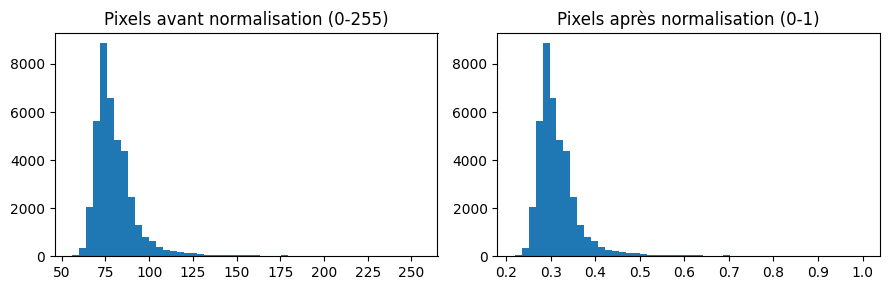


Encodage des classes :
  0 -> crazing
  1 -> inclusion
  2 -> patches
  3 -> pitted_surface
  4 -> rolled-in_scale
  5 -> scratches


In [28]:
sample = next((DATASET_DIR / "train" / "scratches").glob("*"))
raw = cv2.imread(str(sample), cv2.IMREAD_GRAYSCALE)
resized = cv2.resize(raw, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_LINEAR)
normalized = resized.astype("float32") / 255.0

print(f"Brute      : shape={raw.shape}, dtype={raw.dtype}, min={raw.min()}, max={raw.max()}")
print(f"Normalisée : shape={normalized.shape}, dtype={normalized.dtype}, "
      f"min={normalized.min():.2f}, max={normalized.max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(resized.ravel(), bins=50); ax[0].set_title("Pixels avant normalisation (0-255)")
ax[1].hist(normalized.ravel(), bins=50); ax[1].set_title("Pixels après normalisation (0-1)")
plt.tight_layout(); plt.show()

print("\nEncodage des classes :")
for i, c in enumerate(CLASS_NAMES):
    print(f"  {i} -> {c}")

In [29]:
!mkdir -p /content/drive/MyDrive/metal-defect-detection/results
!cp -r /content/metal-defect-detection/results/. /content/drive/MyDrive/metal-defect-detection/results/

## 6. Observations

*À compléter par Personne 1 :* classes équilibrées ? classes visuellement proches (ex. crazing / rolled-in scale) ?
Difficultés prévisibles pour le modèle ?